# One building, from assumptions to results

Follow the full lifecycle and distinguish physical inputs, geometric inspection, compilation and accepted simulation output.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** installed epsm_viewer wheel with notebook extra; local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

The central object is an immutable `BuildingSpec`: a validated description of **what building to model**, not a running simulation. The repository's `building()` helper constructs one using the assumptions in `examples/building.py`. Those demonstration values are not universal EPSM defaults.

The three stages return different evidence: `compile(b)` returns an epJSON dictionary and `CompilationReport`; `run(b, directory)` returns a `SimulationResult` after engine and output checks. `preview(b)` is a teaching helper that displays a static rendering and, by default, an embedded widget. Follow the workflow figure from geometry inspection to the full building before treating a displayed shape as an energy result.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Build an explicit specification

The factory uses the repository example: concrete and insulation layers, 20% WWR, ventilation with heat recovery and constant use schedules. These are illustrative values. Immutable updates validate every replacement.

### Read the code and output

Read the input table before the plot: conditioned floor area is the denominator for EUI, wall U-value describes a nominal assembly, and the weather hash identifies the actual file contents. To change one input, use a validated replacement such as `b.updated(use=b.use.updated(heating_setpoint=ScheduleSpec.constant(20)))`; the original `b` remains unchanged. `preview(b)` displays its widget once; use `scene_widget(b.scene())` directly to retain a handle.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

,field,value
0,identifier,demo
1,floor_area_m2,1800.0
2,wall_U_W_m2K,0.24766899766899764
3,weather_sha256,99f6df726debe1f7df19317227ced9685fa3cf9d031bd5...
4,physical_hash,f4719311c3a1bdf3951b730c9b161b33bc83cfadb087d3...


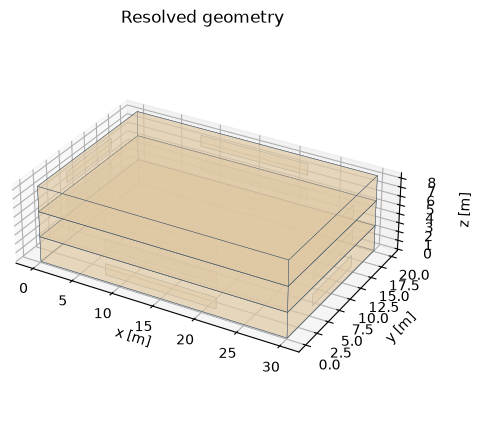

None

In [2]:
# Start by creating a building object.
# This uses explicit demo assumptions from examples/building.py, not universal package defaults.
# Use validated b.updated(...) replacements to vary one input while retaining the baseline.
b = building()

# We can use the demo support function "table" to display some of the building's properties in a table format.
table({"identifier": b.identifier,
       "floor_area_m2": b.geometry.conditioned_floor_area_m2,
       "wall_U_W_m2K": b.envelope.wall.u_value_w_m2k,
       "weather_sha256": b.climate.weather_sha256,
       "physical_hash": b.physical_hash()})

# preview() shows a static image and, by default, an embedded interactive widget.
widget = preview(b)
display(widget)

# Use assert statements to validate that the building's properties are as expected.
assert b.geometry.conditioned_floor_area_m2 > 0

## Compile before running

Compilation produces EnergyPlus input and an audit report. Surface validation is necessary, but an accepted simulation still requires engine diagnostics.

### Read the code and output

The number of entries in `model` counts EnergyPlus object **types**, while `len(model["Zone"])` counts zones. Neither is a measure of simulation accuracy. The report connects emitted geometry to its input ownership and records acceptance checks. Inspect it when a shape looks plausible but compilation rejects an opening or boundary.

In [3]:
compiler = EnergyPlusCompiler(engine())
model, report = compiler.compile(b)
assert report.data["validation"]["surface_count"] > 0
t_model_values = table({"run_id": report.run_id, "zones": len(model["Zone"]), "objects": len(model)})

,field,value
0,run_id,a6458f1aa204e03ad323116db75f16795ca690123324c0...
1,zones,3
2,objects,37


## Run and reconcile annual energy

The runner requires an empty run directory. Three charts separate annual totals, seasonal behaviour and an hourly example. Hourly kWh are interval energy, not instantaneous design loads.

### Read the code and output

The annual bars answer “how much thermal energy?”, the monthly bars show seasonality, and the first-week curves show timing. The equality assertion reconciles heating kWh across those time scales. It does not compare against metered energy. Keep the run ID and diagnostics alongside the plots when sharing a result.

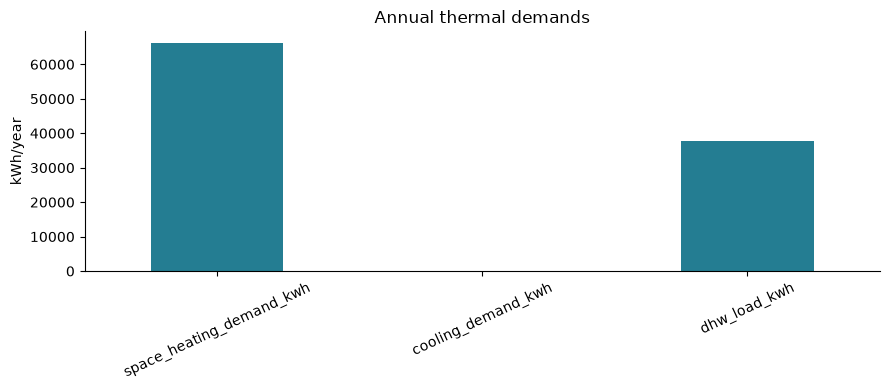

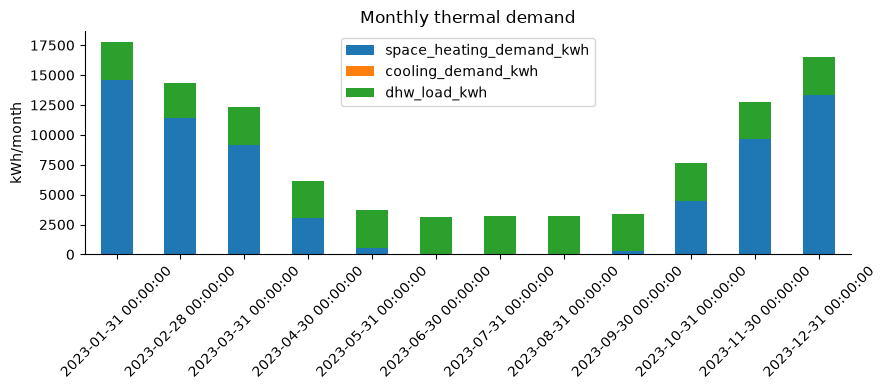

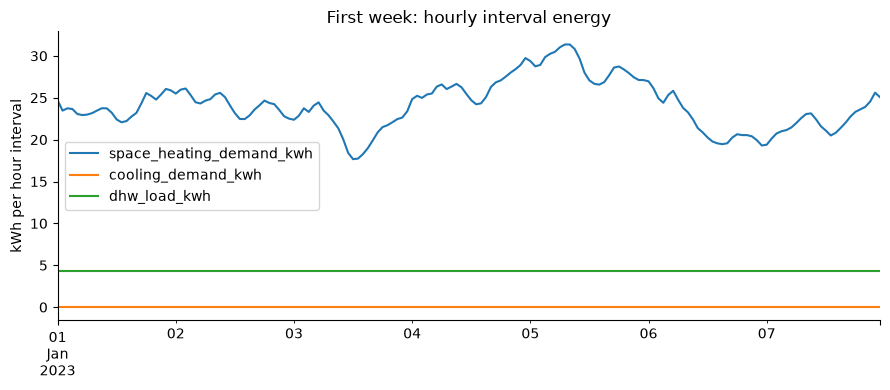

,field,value
0,policy_version,strict-1
1,engine_version,24.2
2,messages,[]
3,accepted,True
4,warning_count,0
5,severe_count,0
6,fatal_count,0
7,invalid_view_factor_count,0
8,err_path,/Users/ssanjay/GitHub/epsm_core/output/demo/00...
9,zoning,"{'effective_mode': 'per_storey', 'on_failure':..."


In [4]:
# empty run directory
result = EnergyPlusRunner(engine()).run(b, OUT / "run")
assert isinstance(result, SimulationResult)
assert np.isclose(result.hourly["space_heating_demand_kwh"].sum(), result.scalars["space_heating_demand_kwh"])
frame = result_plots(result)
t_diagnostics = table(result.diagnostics)

## Interpretation and next experiment

This sequence is the unit of work a stock workflow repeats. Keep the exact weather identity and physical assumptions, not just the final EUI.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.